# import packages

In [1]:
import pandas as pd
import numpy as np
import xarray as xr
import glob, os
from tqdm import tqdm
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor, as_completed

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


# process data to generic data loader format for NH

### user settings

In [2]:
data_dir       = '/Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/'
start_date     = '1980-01-01'
end_date       = '2024-12-31'
time_dim_name  = 'date'
basin_dim_name = 'basin_id'

### read-in basin list

In [4]:
# read in basin list
basin_id_list = '/Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/nasa_co_swe/basin_txt_files/camels_671.txt'
df_basins = pd.read_csv(basin_id_list, header=None)
df_basins = df_basins.applymap(lambda x: str(x).zfill(8)).iloc[:,0].values # convert to 8 digit strings

/var/folders/yt/dy7r_kcj4hd9s492w62q74t40000gp/T/ipykernel_56028/116814713.py:4: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_basins = df_basins.applymap(lambda x: str(x).zfill(8)).iloc[:,0].values # convert to 8 digit strings


### SWE training data

In [5]:
# read in SNOTEL swe data
file = os.path.join(data_dir, 'CAMELS_US/colorado_swe', 'co_camels_snotel_time_series.csv')
co_swe = pd.read_csv(file, index_col=0, parse_dates=True)
co_swe_mean = co_swe.mean(axis=1)

# repeat mean swe df to match basin list length
df_swe = pd.concat([co_swe_mean] * len(df_basins), axis=1)
df_swe.columns = df_basins.squeeze()  # from above list
df_swe.index.name = time_dim_name

# make empty df to match standardized date range
fill_dates = pd.date_range(start=start_date, end=end_date)
empty_df = pd.DataFrame(index=fill_dates, columns=df_swe.columns)
empty_df[:] = np.nan

# combine dfs to match time dims of padded df (start_date - end_date)
df_swe_padded = empty_df.combine_first(df_swe)
df_swe_padded = df_swe_padded.astype('float')

# to netcdf
data_array = xr.DataArray(
    df_swe_padded.values,
    coords={
        time_dim_name: df_swe_padded.index,
        basin_dim_name: df_swe_padded.columns.astype('str')
    },
    dims=[time_dim_name, basin_dim_name],
    name='mean_co_swe'  # Variable name
)
ds_swe = xr.Dataset({'mean_co_swe': data_array})

# save out
out_file = os.path.join(data_dir, 'nasa_co_swe/time_series/working_data', 'swe_all.nc')
if os.path.exists(out_file):
    os.remove(out_file)
print('saving out: ' + out_file)
ds_swe.to_netcdf(out_file, unlimited_dims=[time_dim_name])

saving out: /Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/swe_all.nc


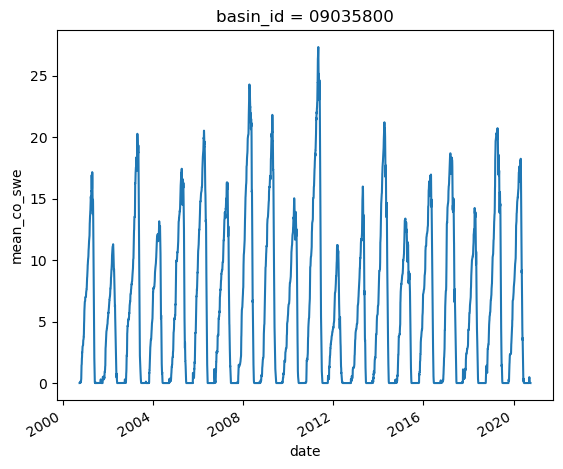

In [6]:
ds_swe.mean_co_swe[:,ds_swe.basin_id == '09035800'].plot()

### specific discharge target var

In [11]:
# get the list of basin_ids
input_path = os.path.join(data_dir, 'nasa_co_swe/time_series/working_data', 'swe_all.nc')
ds_swe     = xr.open_dataset(input_path)
basin_ids  = ds_swe[basin_dim_name].values

# Loop through each basin_id and save to separate NetCDF files
for i, basin_id in tqdm(enumerate(basin_ids)):
    basin_id_str = str(basin_id.zfill(8))  # zero pad 8-digit USGS gage id
    #print(basin_id_str)

    # get filepath for streamflow obs
    file_pattern = os.path.join(data_dir, 'CAMELS_US/usgs_streamflow/*', f'{basin_id_str}_streamflow_qc.txt')
    file_path_q  = list(glob.glob(file_pattern))
    if file_path_q:
        file_path_q = file_path_q[0]
    else:
        raise FileNotFoundError(f'No file for Basin {basin_id_str} at {file_path_q}')
    
    #break

    # Read the CSV file into a pandas DataFrame
    df_q_obs = pd.read_csv(file_path_q, sep='\s+', header=None, names=['index', 'year', 'month', 'day', 'value', 'flag'])

    # Combine year, month, and day columns into a single datetime column, reformat and clean data
    df_q_obs[time_dim_name] = pd.to_datetime(df_q_obs[['year', 'month', 'day']], format='%Y %m %d')
    df_q_obs.set_index(time_dim_name, inplace=True)
    df_q_obs.drop(['index', 'year', 'month', 'day', 'flag'], axis=1, inplace=True)
    df_q_obs[df_q_obs<0] = np.nan

    # Get filepath for basin area from CAMELS forcing
    file_pattern   = os.path.join(data_dir, 'CAMELS_US/basin_mean_forcing/daymet/*', f'{basin_id_str}*.txt')
    file_path_area = list(glob.glob(file_pattern))
    if file_path_area:
        file_path_area = file_path_area[0]
    else:
        raise FileNotFoundError(f'No file for Basin {basin_id_str} at {file_path_area}')
    
    # read in forcing data for area
    df_forc = pd.read_csv(file_path_area)
    basin_area_m2 = float(df_forc.iloc[1,0])

    # normalize discharge from CFS to mm/day
    df_spec_dischrage_obs = 28316846.592 * df_q_obs * 86400 / (basin_area_m2 * 10**6)
    df_spec_dischrage_obs.rename(columns={'value': basin_id_str}, inplace=True)

    # concat discharge for each basin to single df
    if i == 0:
        df_q_all = df_spec_dischrage_obs
    else:
        df_q_all = pd.concat([df_q_all, df_spec_dischrage_obs], axis=1)
    
    # break

# make empty df to match standardized date range
fill_dates = pd.date_range(start=start_date, end=end_date)
empty_df = pd.DataFrame(index=fill_dates, columns=df_q_all.columns)
empty_df[:] = np.nan

# combine dfs
df_q_padded = empty_df.combine_first(df_q_all)
df_q_padded = df_q_padded.astype('float')

# to netcdf
data_array = xr.DataArray(
df_q_padded.values,
coords={
    time_dim_name: df_q_padded.index,
    basin_dim_name: df_q_padded.columns.astype('str')
},
dims=[time_dim_name, basin_dim_name],
name='QObs'  # Variable name
)
ds_q = xr.Dataset({'QObs': data_array})

# save out
out_file = os.path.join(data_dir, 'nasa_co_swe/time_series/working_data', 'QObs_all.nc')
if os.path.exists(out_file):
    os.remove(out_file)
print('saving out: ' + out_file)
ds_q.to_netcdf(out_file, unlimited_dims=[time_dim_name])

671it [00:25, 25.84it/s]


saving out: /Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/QObs_all.nc


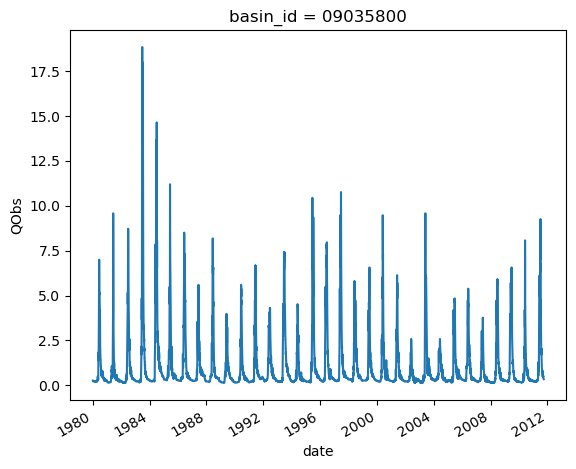

In [13]:
ds_q.QObs[:,ds_q.basin_id == '09035800'].plot()

#df_q_obs

### antecedent streamflow

saving out: /Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/QObs_antecedent.nc


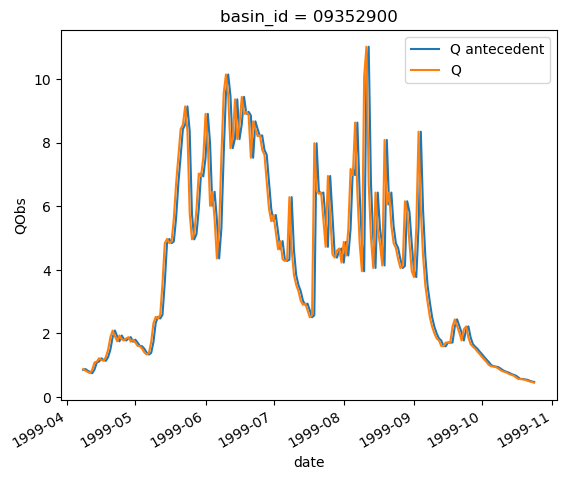

In [32]:
n_shift=1  # shift forward one timestep (day)
in_file = os.path.join(data_dir, 'nasa_co_swe/time_series/working_data', 'QObs_all.nc')

# read in Qobs, shift by N
ds = xr.open_dataset(in_file)
ds_shifted = ds.shift(date=n_shift)
ds_shifted = ds_shifted.rename_vars({'QObs': 'QObs_antecedent'})

# save out
out_file = os.path.join(data_dir, 'nasa_co_swe/time_series/working_data', 'QObs_antecedent.nc')
if os.path.exists(out_file):
    os.remove(out_file)
print('saving out: ' + out_file)
ds_new.to_netcdf(out_file, unlimited_dims=[time_dim_name])

# check plot for random dates
ds_shifted.QObs_antecedent[-9400:-9200,500].plot(label='Q antecedent')
ds.QObs[-9400:-9200,500].plot(label='Q')
plt.legend()

### reformat forcing

In [33]:
# read in forcing files
forc_file_pattern = os.path.join(data_dir, 'CAMELS_US/basin_mean_forcing/nldas_climater/', '*.csv')
time_chunk_size  = 100
basin_chunk_size = 671

# Loop through forcing files
for i, forc_file in enumerate(glob.glob(forc_file_pattern)):
    #print(file)

    # get file and variable name
    filename = os.path.basename(forc_file)
    var = filename.replace('camels_', '').rstrip('_qc.csv')
    
    # read in file
    df_forc = pd.read_csv(forc_file, index_col=0, parse_dates=True)

    # ensure 8-digit USGS column name, other qa/qc
    padded_column_names = [str(col).zfill(8) for col in df_forc.columns]
    df_forc.index.name = time_dim_name
    df_forc.columns    = padded_column_names
    df_forc = df_forc[~df_forc.index.duplicated(keep='first')]  # QA/QC: drop any duplicate dates
    print('length of forcing file' + filename +' is: ' + str(len(df_forc.index)))
    
    # make empty df to match standardized date range
    fill_dates = pd.date_range(start=start_date, end=end_date)
    empty_df = pd.DataFrame(index=fill_dates, columns=df_forc.columns)
    empty_df[:] = np.nan

    # combine dfs
    df_forc_padded = empty_df.combine_first(df_forc)
    df_forc_padded = df_forc_padded.astype('float')
    
    # to netcdf
    data_array = xr.DataArray(
        df_forc_padded.values,
        coords={
            time_dim_name: df_forc_padded.index,
            basin_dim_name: df_forc_padded.columns
        },
        dims=[time_dim_name, basin_dim_name],
        name=var  # Variable name
    )
    ds = xr.Dataset({var: data_array})

    # save out by variable
    out_file = os.path.join(data_dir, 'nasa_co_swe/time_series/working_data', 'forc_all.' + var + '.nc')
    if os.path.exists(out_file):
        os.remove(out_file)
    print('saving out ' + out_file)
    ds.to_netcdf(out_file, unlimited_dims=[time_dim_name])
    #ds.to_netcdf(out_file, unlimited_dims=[time_dim_name], format='NETCDF4', engine='netcdf4', encoding={var: {'chunksizes': (time_chunk_size, basin_chunk_size)}})


length of forcing filecamels_wind_n_qc.csv is: 16384
saving out /Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/forc_all.wind_n.nc
length of forcing filecamels_rainf_qc.csv is: 16384
saving out /Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/forc_all.rainf.nc
length of forcing filecamels_lwdown_qc.csv is: 16384
saving out /Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/forc_all.lwdown.nc
length of forcing filecamels_swdown_qc.csv is: 16384
saving out /Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/forc_all.swdown.nc
length of forcing filecamels_tair_max_qc.csv is: 16384
saving out /Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/forc_all.tair_max.n

### concat together nc files

In [3]:
# find training data nc files
file_pattern = os.path.join(data_dir, 'nasa_co_swe/time_series/working_data', '*.nc')
file_list    = list(glob.glob(file_pattern))
print(file_list)

# Open multiple files as a single dataset
ds_all = xr.open_mfdataset(file_list, combine='by_coords')
print(ds_all)

# Save the concatenated dataset to a new NetCDF file
out_file = os.path.join(data_dir, 'nasa_co_swe/time_series', 'all_training_data.nc')
if os.path.exists(out_file):
    os.remove(out_file)
print('saving out: ' + out_file)
ds_all.to_netcdf(out_file, unlimited_dims=[time_dim_name])

['/Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/forc_all.wind_n.nc', '/Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/forc_all.psurf.nc', '/Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/forc_all.tair_max.nc', '/Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/forc_all.cape.nc', '/Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/forc_all.wind_e.nc', '/Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/QObs_all.nc', '/Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/nasa_co_swe/time_series/working_data/forc_all.qair.nc', '/Users/joshsturtevant/Documents/lyn

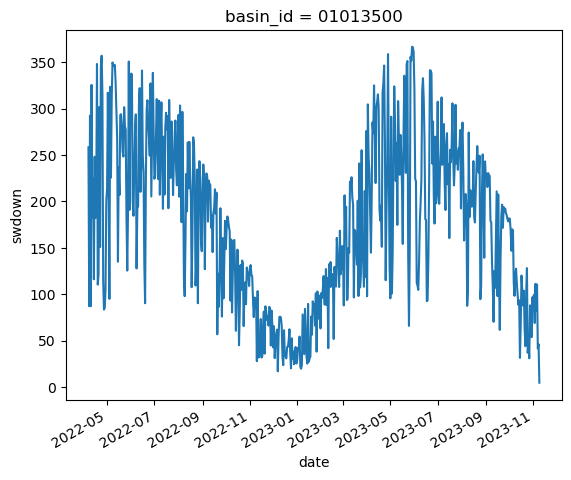

In [4]:
ds_all.swdown[-1000:,0].plot()
#ds_all.wind_e[-1000:,0].plot()

### save out nc file by basin

### single thread

In [12]:
# Path to the input NetCDF file
input_path = os.path.join(data_dir, 'nasa_co_swe/time_series', 'all_training_data.nc')

# Open the original NetCDF file
ds = xr.open_dataset(input_path)

# Get the list of unique basin_ids
basin_ids = ds['basin_id'].values

# # optional: loop through subset basin id list (for testing)
# input_path = '/Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/nasa_co_swe/basin_txt_files/co_camels_basins.v1.txt'
# basin_ids = pd.read_csv(input_path, header=None)[0].to_list()
# basin_ids = [str(basin_id).zfill(8) for basin_id in basin_ids]

# Loop through each basin_id and save to separate NetCDF files
for basin_id in tqdm(basin_ids):
    # Select data for the current basin_id
    basin_ds = ds.sel(basin_id=basin_id)
    basin_ds = basin_ds.drop_vars('basin_id')
    
    # Define output path for the current basin_id (required format for generic data loader)
    out_file = os.path.join(data_dir, 'nasa_co_swe/time_series', f'{basin_id}.nc')
    if os.path.exists(out_file):
        os.remove(out_file)

    # Save the dataset to a new NetCDF file
    basin_ds.to_netcdf(out_file)

  0%|          | 3/671 [00:14<53:10,  4.78s/it]


KeyboardInterrupt: 

### multi-thread

In [3]:
# Path to the input NetCDF file
input_path = os.path.join(data_dir, 'nasa_co_swe/time_series', 'all_training_data.nc')

# Open the original NetCDF file
ds = xr.open_dataset(input_path)

# Get the list of unique basin_ids
basin_ids = ds['basin_id'].values

# Function to save basin data to NetCDF
def save_basin_data(basin_id):
    basin_ds = ds.sel(basin_id=basin_id).drop_vars('basin_id')
    out_file = os.path.join(data_dir, 'nasa_co_swe/time_series', f'{basin_id}.nc')
    
    if os.path.exists(out_file):
        os.remove(out_file)
    
    basin_ds.to_netcdf(out_file)

# Use ThreadPoolExecutor to parallelize the saving process
with ThreadPoolExecutor() as executor:
    futures = [executor.submit(save_basin_data, basin_id) for basin_id in basin_ids]
    
    for future in tqdm(as_completed(futures), total=len(basin_ids)):
        pass  # Wait for all tasks to complete

print("All NetCDF files saved successfully.")


  0%|          | 0/671 [00:00<?, ?it/s]

### spot check

<xarray.Dataset>
Dimensions:      (date: 16802)
Coordinates:
  * date         (date) datetime64[ns] 1979-01-01 1979-01-02 ... 2024-12-31
Data variables:
    QObs         (date) float64 ...
    cape         (date) float64 ...
    crainf_fra   (date) float64 ...
    lwdown       (date) float64 ...
    mean_co_swe  (date) float64 ...
    psurf        (date) float64 ...
    qair         (date) float64 ...
    rainf        (date) float64 ...
    swdown       (date) float64 ...
    tair_max     (date) float64 ...
    tair_min     (date) float64 ...


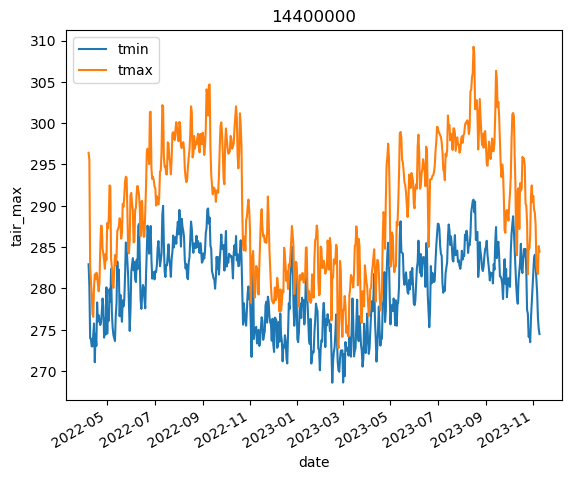

In [5]:
basin_id = '14400000'
file_in = os.path.join(data_dir, 'nasa_co_swe/time_series', f'{basin_id}.nc')

ds = xr.open_dataset(file_in)
print(ds)

ds.tair_min[-1000:].plot(label='tmin')
ds.tair_max[-1000:].plot(label='tmax')
plt.title(basin_id)
plt.legend()

### check qobs missing data

<xarray.Dataset>
Dimensions:      (date: 16802, basin_id: 671)
Coordinates:
  * date         (date) datetime64[ns] 1979-01-01 1979-01-02 ... 2024-12-31
  * basin_id     (basin_id) object '01013500' '01022500' ... '14400000'
Data variables:
    QObs         (date, basin_id) float64 ...
    cape         (date, basin_id) float64 ...
    crainf_fra   (date, basin_id) float64 ...
    lwdown       (date, basin_id) float64 ...
    mean_co_swe  (date, basin_id) float64 ...
    psurf        (date, basin_id) float64 ...
    qair         (date, basin_id) float64 ...
    rainf        (date, basin_id) float64 ...
    swdown       (date, basin_id) float64 ...
    tair_max     (date, basin_id) float64 ...
    tair_min     (date, basin_id) float64 ...
date
Error plotting missing data for date: 'basin_id' not found in array dimensions ('date',)
basin_id
Error plotting missing data for basin_id: No numeric data to plot.
QObs


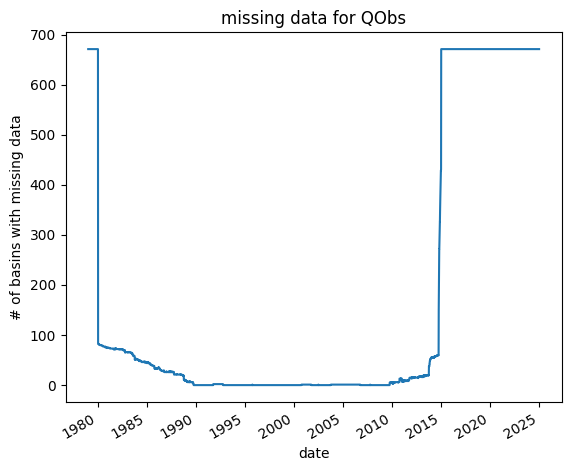

cape


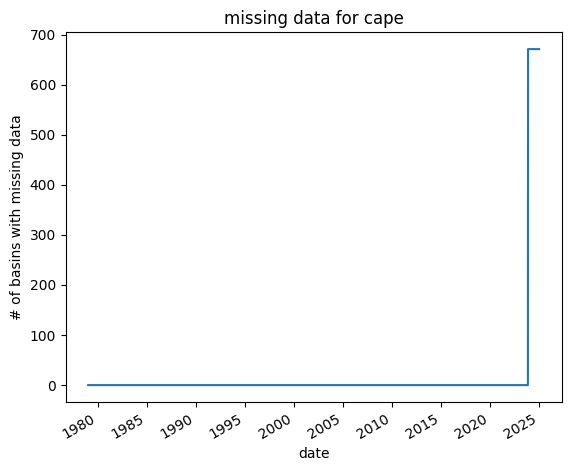

crainf_fra


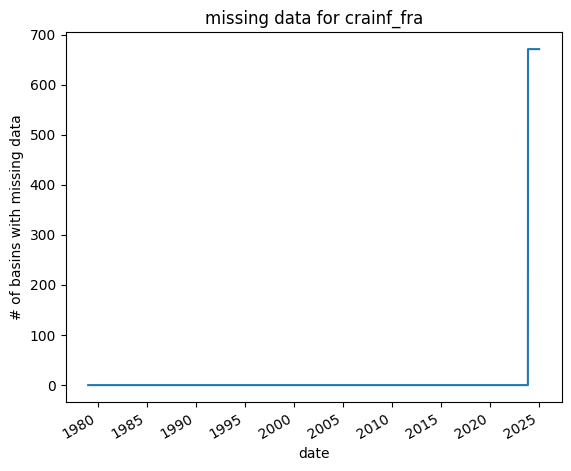

lwdown


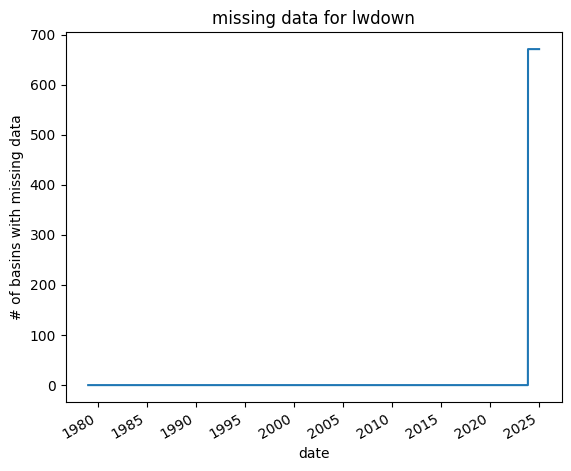

mean_co_swe


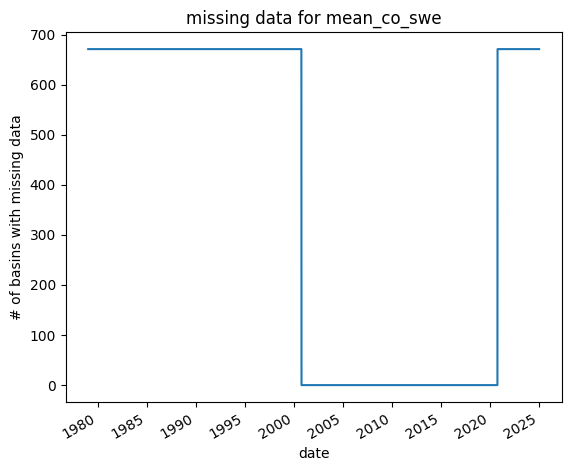

psurf


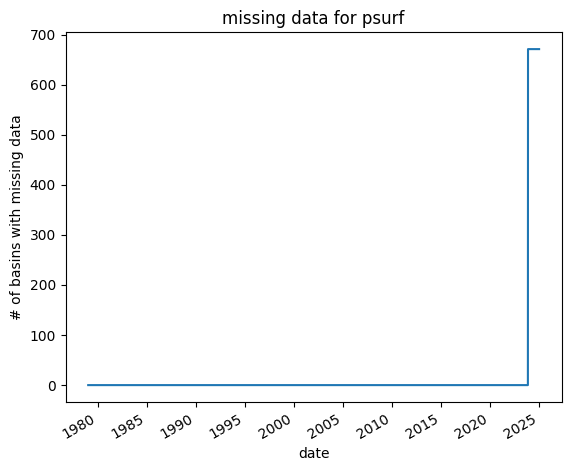

qair


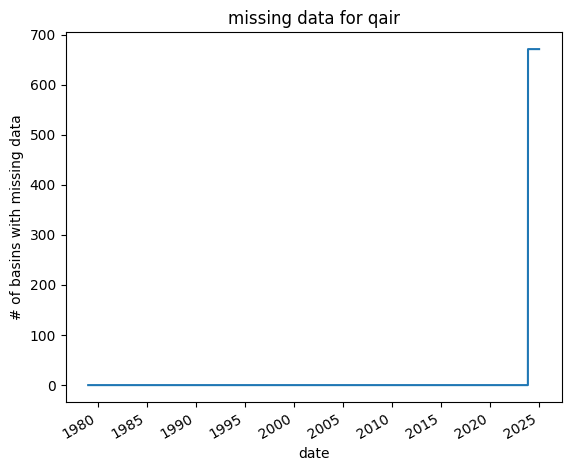

rainf


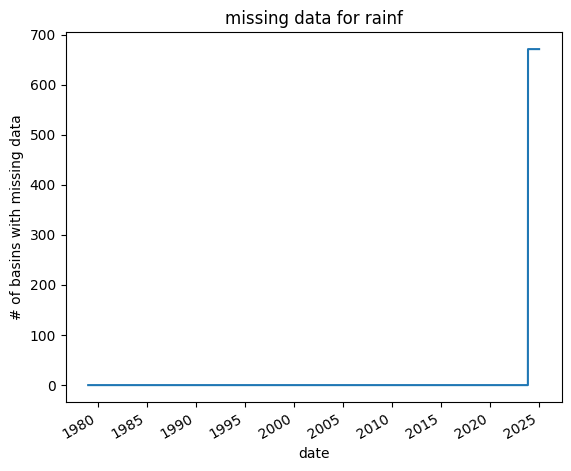

swdown


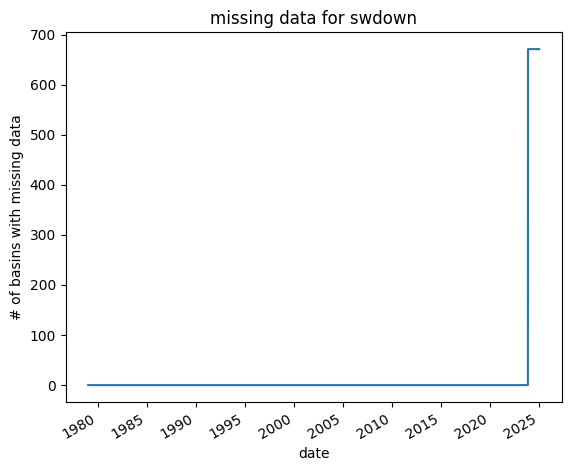

tair_max


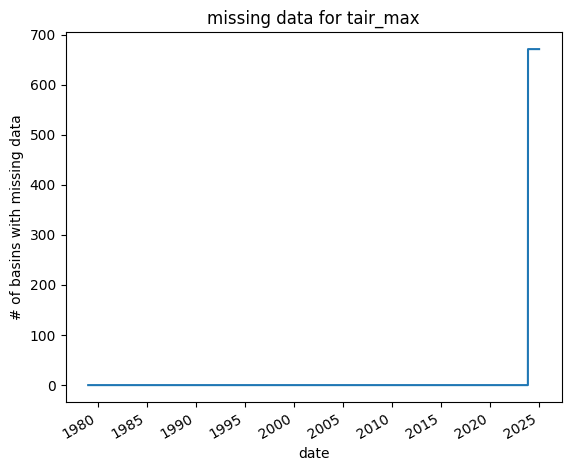

tair_min


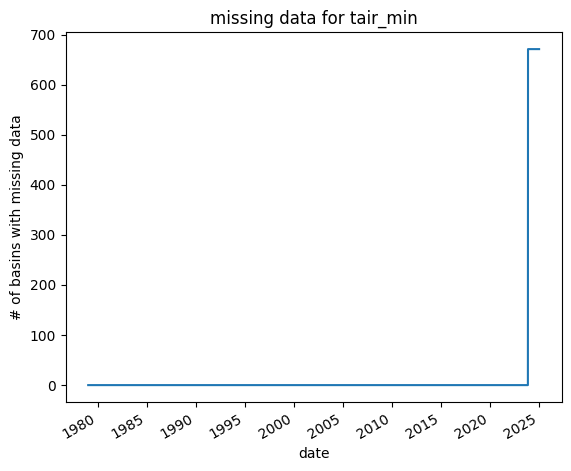

In [189]:
# read in all training data
input_path = os.path.join(data_dir, 'nasa_co_swe/time_series', 'all_training_data.nc')
ds = xr.open_dataset(input_path)
print(ds)

# loop through vars in ds
for var_name in ds.variables:
    var_data = ds[var_name]  # Access the DataArray for the variable
    print(var_name)

    # plot missing data
    try:
        ds.isnull()[var_name].sum(dim='basin_id').plot()
        plt.title('missing data for ' + var_name)
        plt.ylabel('# of basins with missing data')
        plt.show()
        plt.close()
    except Exception as e:
        print(f"Error plotting missing data for {var_name}: {e}")